In [ ]:
from pathlib import Path
from dotenv import load_dotenv, dotenv_values
import os

PROJECT_DIR = Path(r"D:\wildlife")
ENV_PATH = PROJECT_DIR / ".env"

print("Environment file exists:", ENV_PATH.exists())

# Read the environment file without displaying secrets
config = dotenv_values(ENV_PATH)

print("Variables found:", list(config.keys()))
print("IUCN_API_KEY present:", bool(config.get("IUCN_API_KEY")))

# Load environment variables
load_dotenv(ENV_PATH, override=True)

API_KEY = os.getenv("IUCN_API_KEY")

print("Token loaded:", bool(API_KEY))
print("Token length:", len(API_KEY) if API_KEY else 0)

Environment file exists: True
Variables found: ['IUCN_API_KEY']
IUCN_API_KEY present: True
Token loaded: True
Token length: 41


In [12]:
BASE_URL = "https://api.iucnredlist.org/api/v4"

headers = {
    "Authorization": f"Bearer {API_KEY}",
    "Accept": "application/json"
}

url = f"{BASE_URL}/information/red_list_version"

response = requests.get(
    url,
    headers=headers,
    timeout=30
)

print("HTTP Status:", response.status_code)

if response.status_code == 200:
    print("Authentication successful!")
    print("IUCN Red List version:", response.json())

elif response.status_code == 401:
    print("Authentication failed. Check your API token.")

elif response.status_code == 403:
    print("Access forbidden. Check your API permissions.")

else:
    print("API error:", response.text[:500])

HTTP Status: 200
Authentication successful!
IUCN Red List version: {'red_list_version': '2026-1'}


In [13]:
import requests
import json

url = f"{BASE_URL}/taxa/class/Mammalia"

response = requests.get(
    url,
    headers=headers,
    params={"page": 1},
    timeout=60
)

print("HTTP Status:", response.status_code)

response.raise_for_status()

mammal_data = response.json()

print("\nResponse keys:")
print(list(mammal_data.keys()))

print("\nResponse preview:")
print(json.dumps(mammal_data, indent=2)[:4000])

HTTP Status: 200

Response keys:
['assessments', 'filters']

Response preview:
{
  "assessments": [
    {
      "assessment_date": "2016-08-11T01:00:00.000+01:00",
      "year_published": "2016",
      "latest": false,
      "possibly_extinct": false,
      "possibly_extinct_in_the_wild": false,
      "sis_taxon_id": 11481,
      "criteria": null,
      "url": "https://www.iucnredlist.org/species/11481/503146",
      "taxon_scientific_name": "Lemmus lemmus",
      "red_list_category_code": "LC",
      "assessment_id": 503146,
      "scopes": [
        {
          "description": {
            "en": "Global"
          },
          "code": "1"
        },
        {
          "description": {
            "en": "Europe"
          },
          "code": "2"
        }
      ]
    },
    {
      "assessment_date": "2018-06-01T01:00:00.000+01:00",
      "year_published": "2019",
      "latest": false,
      "possibly_extinct": false,
      "possibly_extinct_in_the_wild": false,
      "sis_taxon_id

In [14]:
assessments = mammal_data.get("assessments", [])

print("Assessments retrieved:", len(assessments))

if assessments:
    print("\nAvailable assessment fields:")
    print(list(assessments[0].keys()))

    print("\nFirst assessment:")
    display(pd.json_normalize(assessments).head())
else:
    print("No assessments found. Inspect the API response.")

Assessments retrieved: 100

Available assessment fields:
['assessment_date', 'year_published', 'latest', 'possibly_extinct', 'possibly_extinct_in_the_wild', 'sis_taxon_id', 'criteria', 'url', 'taxon_scientific_name', 'red_list_category_code', 'assessment_id', 'scopes']

First assessment:


,assessment_date,year_published,latest,possibly_extinct,possibly_extinct_in_the_wild,sis_taxon_id,criteria,url,taxon_scientific_name,red_list_category_code,assessment_id,scopes
0,2016-08-11T01:00:00.000+01:00,2016,False,False,False,11481,NaN,https://www.iucnredlist.org/species/11481/503146,Lemmus lemmus,LC,503146,"[{'description': {'en': 'Global'}, 'code': '1'..."
1,2018-06-01T01:00:00.000+01:00,2019,False,False,False,11797,B1ab(v),https://www.iucnredlist.org/species/11797/503908,Lepus castroviejoi,VU,503908,"[{'description': {'en': 'Global'}, 'code': '1'..."
2,2011-06-30T01:00:00.000+01:00,2012,False,False,False,12817,NaN,https://www.iucnredlist.org/species/12817/509971,Marmosops cracens,DD,509971,"[{'description': {'en': 'Global'}, 'code': '1'}]"
3,2016-02-18T00:00:00.000+00:00,2016,False,False,False,12835,NaN,https://www.iucnredlist.org/species/12835/510082,Marmota marmota,LC,510082,"[{'description': {'en': 'Global'}, 'code': '1'..."
4,2018-06-19T01:00:00.000+01:00,2019,False,False,False,13462,NaN,https://www.iucnredlist.org/species/13462/513175,Microtus felteni,LC,513175,"[{'description': {'en': 'Global'}, 'code': '1'..."


In [15]:
url = f"{BASE_URL}/taxa/class/Mammalia"

params = {
    "page": 1,
    "latest": "true",
    "scope_code": 1
}

response = requests.get(
    url,
    headers=headers,
    params=params,
    timeout=60
)

print("HTTP Status:", response.status_code)
response.raise_for_status()

filtered_data = response.json()

filtered_assessments = filtered_data.get("assessments", [])

print("Filtered assessments:", len(filtered_assessments))

filtered_df = pd.json_normalize(filtered_assessments)

display(filtered_df.head())

HTTP Status: 200
Filtered assessments: 100


,assessment_date,year_published,latest,possibly_extinct,possibly_extinct_in_the_wild,sis_taxon_id,criteria,url,taxon_scientific_name,red_list_category_code,assessment_id,scopes
0,2016-04-25T01:00:00.000+01:00,2016,True,False,False,136680,NaN,https://www.iucnredlist.org/species/136680/518740,Myotis alcathoe,DD,518740,"[{'description': {'en': 'Global'}, 'code': '1'..."
1,2017-02-28T00:00:00.000+00:00,2018,True,False,False,15602,"B2ab(i,iii)",https://www.iucnredlist.org/species/15602/739675,Euryoryzomys lamia,VU,739675,"[{'description': {'en': 'Global'}, 'code': '1'}]"
2,2014-11-18T00:00:00.000+00:00,2015,True,False,False,17026,A4bd,https://www.iucnredlist.org/species/17026/1306343,Phocarctos hookeri,EN,1306343,"[{'description': {'en': 'Global'}, 'code': '1'}]"
3,2023-02-27T00:00:00.000+00:00,2024,True,False,False,2150,A2ace,https://www.iucnredlist.org/species/2150/2775649,Arvicola sapidus,NT,2775649,"[{'description': {'en': 'Global'}, 'code': '1'..."
4,2023-02-27T00:00:00.000+00:00,2024,True,False,False,7618,A2c,https://www.iucnredlist.org/species/7618/3139783,Eliomys quercinus,VU,3139783,"[{'description': {'en': 'Global'}, 'code': '1'..."


In [16]:
import time
from pathlib import Path

OUTPUT_DIR = Path(r"D:\wildlife\datasets\iucn")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CSV_PATH = OUTPUT_DIR / "iucn_mammals.csv"

all_assessments = []

page = 1
page_size = 100

while True:

    print(f"Downloading page {page}...")

    params = {
        "page": page,
        "latest": "true",
        "scope_code": 1
    }

    try:
        response = requests.get(
            f"{BASE_URL}/taxa/class/Mammalia",
            headers=headers,
            params=params,
            timeout=60
        )

        response.raise_for_status()

        data = response.json()

        records = data.get("assessments", [])

        if not records:
            print("No more records.")
            break

        all_assessments.extend(records)

        # Save progress after every page
        temp_df = pd.json_normalize(all_assessments)

        temp_df.to_csv(
            CSV_PATH,
            index=False
        )

        print(
            f"Page {page}: {len(records)} records | "
            f"Total: {len(all_assessments)}"
        )

        if len(records) < page_size:
            break

        page += 1

        # Respect API server resources
        time.sleep(1)

    except requests.exceptions.RequestException as e:

        print("Download interrupted:", e)
        print("Successfully downloaded records are saved.")
        break

print("\nDownload process finished.")
print("Total records:", len(all_assessments))
print("Saved at:", CSV_PATH)

Page 1: 100 records | Total: 100
Page 2: 100 records | Total: 200
Page 3: 100 records | Total: 300
Page 4: 100 records | Total: 400
Page 5: 100 records | Total: 500
Page 6: 100 records | Total: 600
Page 7: 100 records | Total: 700
Page 8: 100 records | Total: 800
Page 9: 100 records | Total: 900
Page 10: 100 records | Total: 1000
Page 11: 100 records | Total: 1100
Page 12: 100 records | Total: 1200
Page 13: 100 records | Total: 1300
Page 14: 100 records | Total: 1400
Page 15: 100 records | Total: 1500
Page 16: 100 records | Total: 1600
Page 17: 100 records | Total: 1700
Page 18: 100 records | Total: 1800
Page 19: 100 records | Total: 1900
Page 20: 100 records | Total: 2000
Page 21: 100 records | Total: 2100
Page 22: 100 records | Total: 2200
Page 23: 100 records | Total: 2300
Page 24: 100 records | Total: 2400
Page 25: 100 records | Total: 2500
Page 26: 100 records | Total: 2600
Page 27: 100 records | Total: 2700
Page 28: 100 records | Total: 2800
Page 29: 100 records | Total: 2900
Pag

In [17]:
iucn_df = pd.read_csv(CSV_PATH)

print("Dataset shape:", iucn_df.shape)

print("\nConservation categories:")
print(iucn_df["red_list_category_code"].value_counts())

print("\nLatest assessment check:")
print(iucn_df["latest"].value_counts())

print("\nMissing values:")
print(iucn_df.isnull().sum())

print("\nUnique species:",
      iucn_df["sis_taxon_id"].nunique())

display(
    iucn_df[
        [
            "taxon_scientific_name",
            "red_list_category_code",
            "assessment_id",
            "assessment_date",
            "year_published"
        ]
    ].head(10)
)

Dataset shape: (6054, 12)

Conservation categories:
red_list_category_code
LC       3407
DD        773
VU        571
EN        565
NT        404
CR        236
EX         96
LR/nt       1
EW          1
Name: count, dtype: int64

Latest assessment check:
latest
True    6054
Name: count, dtype: int64

Missing values:
assessment_date                    0
year_published                     0
latest                             0
possibly_extinct                   0
possibly_extinct_in_the_wild       0
sis_taxon_id                       0
criteria                        4401
url                                0
taxon_scientific_name              0
red_list_category_code             0
assessment_id                      0
scopes                             0
dtype: int64

Unique species: 6054


,taxon_scientific_name,red_list_category_code,assessment_id,assessment_date,year_published
0,Myotis alcathoe,DD,518740,2016-04-25T01:00:00.000+01:00,2016
1,Euryoryzomys lamia,VU,739675,2017-02-28T00:00:00.000+00:00,2018
2,Phocarctos hookeri,EN,1306343,2014-11-18T00:00:00.000+00:00,2015
3,Arvicola sapidus,NT,2775649,2023-02-27T00:00:00.000+00:00,2024
4,Eliomys quercinus,VU,3139783,2023-02-27T00:00:00.000+00:00,2024
5,Nycticeius aenobarbus,DD,4311281,2008-06-30T01:00:00.000+01:00,2008
6,Scotophilus collinus,LC,4318302,2008-06-30T01:00:00.000+01:00,2008
7,Naemorhedus goral,NT,4430073,2008-06-30T01:00:00.000+01:00,2008
8,Ovis nivicola,LC,5076357,2008-06-30T01:00:00.000+01:00,2008
9,Rhinolophus cornutus,LR/nt,8957242,1996-08-01T01:00:00.000+01:00,1996


In [18]:
# Work on a copy of the original dataset
iucn_clean = iucn_df.copy()

# Normalize legacy category
iucn_clean["red_list_category_code"] = (
    iucn_clean["red_list_category_code"]
    .replace({"LR/nt": "NT"})
)

# Keep only categories suitable for binary classification
valid_categories = ["LC", "NT", "VU", "EN", "CR"]

iucn_clean = iucn_clean[
    iucn_clean["red_list_category_code"].isin(valid_categories)
].copy()

# Create binary risk target
iucn_clean["risk_target"] = (
    iucn_clean["red_list_category_code"]
    .isin(["VU", "EN", "CR"])
).astype(int)

# Rename columns
iucn_clean.rename(columns={
    "taxon_scientific_name": "scientific_name",
    "red_list_category_code": "category",
    "sis_taxon_id": "species_id"
}, inplace=True)

print("Cleaned dataset shape:", iucn_clean.shape)

print("\nRisk distribution:")
print(iucn_clean["risk_target"].value_counts())

print("\nCategory distribution:")
print(iucn_clean["category"].value_counts())

display(iucn_clean.head())

Cleaned dataset shape: (5184, 13)

Risk distribution:
risk_target
0    3812
1    1372
Name: count, dtype: int64

Category distribution:
category
LC    3407
VU     571
EN     565
NT     405
CR     236
Name: count, dtype: int64


,assessment_date,year_published,latest,possibly_extinct,possibly_extinct_in_the_wild,species_id,criteria,url,scientific_name,category,assessment_id,scopes,risk_target
1,2017-02-28T00:00:00.000+00:00,2018,True,False,False,15602,"B2ab(i,iii)",https://www.iucnredlist.org/species/15602/739675,Euryoryzomys lamia,VU,739675,"[{'description': {'en': 'Global'}, 'code': '1'}]",1
2,2014-11-18T00:00:00.000+00:00,2015,True,False,False,17026,A4bd,https://www.iucnredlist.org/species/17026/1306343,Phocarctos hookeri,EN,1306343,"[{'description': {'en': 'Global'}, 'code': '1'}]",1
3,2023-02-27T00:00:00.000+00:00,2024,True,False,False,2150,A2ace,https://www.iucnredlist.org/species/2150/2775649,Arvicola sapidus,NT,2775649,"[{'description': {'en': 'Global'}, 'code': '1'...",0
4,2023-02-27T00:00:00.000+00:00,2024,True,False,False,7618,A2c,https://www.iucnredlist.org/species/7618/3139783,Eliomys quercinus,VU,3139783,"[{'description': {'en': 'Global'}, 'code': '1'...",1
6,2008-06-30T01:00:00.000+01:00,2008,True,False,False,136612,NaN,https://www.iucnredlist.org/species/136612/431...,Scotophilus collinus,LC,4318302,"[{'description': {'en': 'Global'}, 'code': '1'}]",0


In [2]:
from pathlib import Path

PROJECT_DIR = Path(r"D:\wildlife")

OUTPUT_DIR = PROJECT_DIR / "datasets" / "iucn"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output directory:", OUTPUT_DIR)
print("Directory exists:", OUTPUT_DIR.exists())

Output directory: D:\wildlife\datasets\iucn
Directory exists: True


In [5]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(r"D:\wildlife")

OUTPUT_DIR = PROJECT_DIR / "datasets" / "iucn"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RAW_PATH = OUTPUT_DIR / "iucn_mammals.csv"

iucn_df = pd.read_csv(RAW_PATH)

print("Original dataset loaded:", iucn_df.shape)

Original dataset loaded: (6054, 12)


In [6]:
iucn_clean = iucn_df.copy()

iucn_clean["red_list_category_code"] = (
    iucn_clean["red_list_category_code"]
    .replace({"LR/nt": "NT"})
)

valid_categories = ["LC", "NT", "VU", "EN", "CR"]

iucn_clean = iucn_clean[
    iucn_clean["red_list_category_code"].isin(valid_categories)
].copy()

iucn_clean["risk_target"] = (
    iucn_clean["red_list_category_code"]
    .isin(["VU", "EN", "CR"])
).astype(int)

iucn_clean.rename(columns={
    "taxon_scientific_name": "scientific_name",
    "red_list_category_code": "category",
    "sis_taxon_id": "species_id"
}, inplace=True)

print("Cleaned dataset:", iucn_clean.shape)
print(iucn_clean["risk_target"].value_counts())

Cleaned dataset: (5184, 13)
risk_target
0    3812
1    1372
Name: count, dtype: int64


In [7]:
CLEAN_PATH = OUTPUT_DIR / "iucn_mammals_cleaned.csv"

iucn_clean.to_csv(CLEAN_PATH, index=False)

print("Saved successfully:", CLEAN_PATH)
print("Final shape:", iucn_clean.shape)

Saved successfully: D:\wildlife\datasets\iucn\iucn_mammals_cleaned.csv
Final shape: (5184, 13)


In [8]:
import pandas as pd
import requests
import time
from pathlib import Path

PROJECT_DIR = Path(r"D:\wildlife")

CLEAN_PATH = (
    PROJECT_DIR / "datasets" / "iucn"
    / "iucn_mammals_cleaned.csv"
)

GBIF_DIR = PROJECT_DIR / "datasets" / "gbif"
GBIF_DIR.mkdir(parents=True, exist_ok=True)

iucn_clean = pd.read_csv(CLEAN_PATH)

print("IUCN species loaded:", len(iucn_clean))
print("GBIF output directory:", GBIF_DIR)

IUCN species loaded: 5184
GBIF output directory: D:\wildlife\datasets\gbif


In [9]:
GBIF_BASE_URL = "https://api.gbif.org/v1"

gbif_session = requests.Session()

gbif_session.headers.update({
    "User-Agent": "WildlifeSpeciesRiskAssessment/1.0"
})

print("GBIF API configured successfully!")

GBIF API configured successfully!


In [10]:
def match_gbif_species(species_name):

    try:
        response = gbif_session.get(
            f"{GBIF_BASE_URL}/species/match",
            params={"name": species_name},
            timeout=30
        )

        response.raise_for_status()
        data = response.json()

        return {
            "requested_name": species_name,
            "gbif_name": data.get("scientificName"),
            "taxon_key": data.get("usageKey"),
            "match_type": data.get("matchType"),
            "rank": data.get("rank"),
            "status": data.get("status")
        }

    except requests.RequestException as e:
        print(f"Error matching {species_name}: {e}")
        return None

In [11]:
sample_species = (
    iucn_clean["scientific_name"]
    .drop_duplicates()
    .head(5)
    .tolist()
)

matches = []

for species in sample_species:

    result = match_gbif_species(species)

    if result:
        matches.append(result)

    time.sleep(0.3)

gbif_matches = pd.DataFrame(matches)

display(gbif_matches)

print("Species tested:", len(sample_species))
print("Successful matches:", gbif_matches["taxon_key"].notna().sum())

,requested_name,gbif_name,taxon_key,match_type,rank,status
0,Euryoryzomys lamia,"Euryoryzomys lamia (Thomas, 1901)",5786859,EXACT,SPECIES,ACCEPTED
1,Phocarctos hookeri,"Phocarctos hookeri (Gray, 1844)",2433467,EXACT,SPECIES,ACCEPTED
2,Arvicola sapidus,"Arvicola sapidus Miller, 1908",2438492,EXACT,SPECIES,ACCEPTED
3,Eliomys quercinus,"Eliomys quercinus (Linnaeus, 1766)",2439683,EXACT,SPECIES,ACCEPTED
4,Scotophilus collinus,"Scotophilus collinus Sody, 1936",5707087,EXACT,SPECIES,ACCEPTED


Species tested: 5
Successful matches: 5


In [12]:
MATCH_PATH = GBIF_DIR / "gbif_taxonomy_pilot.csv"

gbif_matches.to_csv(
    MATCH_PATH,
    index=False
)

print("Matching results saved:", MATCH_PATH)

Matching results saved: D:\wildlife\datasets\gbif\gbif_taxonomy_pilot.csv


In [16]:
import requests
import time
import pandas as pd

def get_gbif_occurrences(taxon_key, limit=100, max_retries=4):

    for attempt in range(max_retries):

        try:
            response = gbif_session.get(
                f"{GBIF_BASE_URL}/occurrence/search",
                params={
                    "taxonKey": int(taxon_key),
                    "hasCoordinate": "true",
                    "hasGeospatialIssue": "false",
                    "occurrenceStatus": "PRESENT",
                    "limit": limit,
                    "offset": 0
                },
                timeout=(15, 90)
            )

            response.raise_for_status()

            data = response.json()

            return {
                "success": True,
                "total_available": data.get("count", 0),
                "records": data.get("results", []),
                "error": None
            }

        except requests.exceptions.RequestException as e:

            wait_time = 2 ** attempt

            print(
                f"Attempt {attempt + 1}/{max_retries} "
                f"failed for {taxon_key}: {e}"
            )

            if attempt < max_retries - 1:
                print(f"Retrying in {wait_time} seconds...")
                time.sleep(wait_time)

    return {
        "success": False,
        "total_available": None,
        "records": [],
        "error": "Maximum retries exceeded"
    }

In [ ]:
# Load existing successful records if available
PILOT_PATH = GBIF_DIR / "gbif_mammals_pilot.csv"

if PILOT_PATH.exists():
    existing_records = pd.read_csv(PILOT_PATH)
else:
    existing_records = pd.DataFrame()

# Identify species already downloaded successfully
completed_species = set()

if not existing_records.empty:
    completed_species = set(
        existing_records["scientific_name"].dropna()
    )

new_records = []
retry_summary = []

for _, row in gbif_matches.iterrows():

    species = row["requested_name"]
    taxon_key = row["taxon_key"]

    if species in completed_species:
        print(f"Skipping already downloaded: {species}")
        continue

    print(f"\nRetrieving: {species}")

    result = get_gbif_occurrences(
        taxon_key,
        limit=100,
        max_retries=4
    )

    retry_summary.append({
        "species": species,
        "success": result["success"],
        "available": result["total_available"],
        "downloaded": len(result["records"]),
        "error": result["error"]
    })

    if result["success"]:

        for record in result["records"]:

            new_records.append({
                "scientific_name": species,
                "gbif_species": record.get("species"),
                "taxon_key": taxon_key,
                "gbif_id": record.get("gbifID"),
                "latitude": record.get("decimalLatitude"),
                "longitude": record.get("decimalLongitude"),
                "event_date": record.get("eventDate"),
                "basis_of_record": record.get("basisOfRecord"),
                "country_code": record.get("countryCode"),
                "coordinate_uncertainty": record.get(
                    "coordinateUncertaintyInMeters"
                )
            })

        print(
            f"Success: {len(result['records'])} records"
        )

        # Save progress after each species
        if new_records:
            combined = pd.concat(
                [
                    existing_records,
                    pd.DataFrame(new_records)
                ],
                ignore_index=True
            )

            combined.drop_duplicates(
                subset="gbif_id",
                inplace=True
            )

            combined.to_csv(
                PILOT_PATH,
                index=False
            )

            existing_records = combined
            new_records = []

    else:
        print("Failed after all retries.")

    time.sleep(2)

retry_summary_df = pd.DataFrame(retry_summary)

display(retry_summary_df)

print("\nTotal saved occurrence records:",
      len(existing_records))

In [20]:
# Load existing successful records if available
PILOT_PATH = GBIF_DIR / "gbif_mammals_pilot.csv"

if PILOT_PATH.exists():
    existing_records = pd.read_csv(PILOT_PATH)
else:
    existing_records = pd.DataFrame()

# Identify species already downloaded successfully
completed_species = set()

if not existing_records.empty:
    completed_species = set(
        existing_records["scientific_name"].dropna()
    )

new_records = []
retry_summary = []

for _, row in gbif_matches.iterrows():

    species = row["requested_name"]
    taxon_key = row["taxon_key"]

    if species in completed_species:
        print(f"Skipping already downloaded: {species}")
        continue

    print(f"\nRetrieving: {species}")

    result = get_gbif_occurrences(
        taxon_key,
        limit=100,
        max_retries=4
    )

    retry_summary.append({
        "species": species,
        "success": result["success"],
        "available": result["total_available"],
        "downloaded": len(result["records"]),
        "error": result["error"]
    })

    if result["success"]:

        for record in result["records"]:

            new_records.append({
                "scientific_name": species,
                "gbif_species": record.get("species"),
                "taxon_key": taxon_key,
                "gbif_id": record.get("gbifID"),
                "latitude": record.get("decimalLatitude"),
                "longitude": record.get("decimalLongitude"),
                "event_date": record.get("eventDate"),
                "basis_of_record": record.get("basisOfRecord"),
                "country_code": record.get("countryCode"),
                "coordinate_uncertainty": record.get(
                    "coordinateUncertaintyInMeters"
                )
            })

        print(
            f"Success: {len(result['records'])} records"
        )

        # Save progress after each species
        if new_records:
            combined = pd.concat(
                [
                    existing_records,
                    pd.DataFrame(new_records)
                ],
                ignore_index=True
            )

            combined.drop_duplicates(
                subset="gbif_id",
                inplace=True
            )

            combined.to_csv(
                PILOT_PATH,
                index=False
            )

            existing_records = combined
            new_records = []

    else:
        print("Failed after all retries.")

    time.sleep(2)

retry_summary_df = pd.DataFrame(retry_summary)

display(retry_summary_df)

print("\nTotal saved occurrence records:",
      len(existing_records))


Retrieving: Euryoryzomys lamia
Attempt 1/4 failed for 5786859: HTTPSConnectionPool(host='api.gbif.org', port=443): Read timed out. (read timeout=15)
Retrying in 1 seconds...
Attempt 2/4 failed for 5786859: HTTPSConnectionPool(host='api.gbif.org', port=443): Read timed out.
Retrying in 2 seconds...
Success: 4 records

Retrieving: Phocarctos hookeri
Attempt 1/4 failed for 2433467: HTTPSConnectionPool(host='api.gbif.org', port=443): Read timed out.
Retrying in 1 seconds...
Attempt 2/4 failed for 2433467: HTTPSConnectionPool(host='api.gbif.org', port=443): Read timed out.
Retrying in 2 seconds...
Success: 100 records

Retrieving: Arvicola sapidus
Success: 100 records

Retrieving: Eliomys quercinus
Attempt 1/4 failed for 2439683: HTTPSConnectionPool(host='api.gbif.org', port=443): Read timed out.
Retrying in 1 seconds...
Attempt 2/4 failed for 2439683: ('Connection broken: IncompleteRead(1458176 bytes read, 1114731 more expected)', IncompleteRead(1458176 bytes read, 1114731 more expected))

,species,success,available,downloaded,error
0,Euryoryzomys lamia,True,4,4,None
1,Phocarctos hookeri,True,36499,100,None
2,Arvicola sapidus,True,17364,100,None
3,Eliomys quercinus,True,28132,100,None
4,Scotophilus collinus,True,1,1,None



Total saved occurrence records: 305


In [22]:
gbif_pilot = pd.read_csv(PILOT_PATH)

print("Dataset shape:", gbif_pilot.shape)

print("\nMissing values:")
print(gbif_pilot.isnull().sum())

print("\nDuplicate GBIF IDs:")
print(gbif_pilot["gbif_id"].duplicated().sum())

print("\nRecords per species:")
print(gbif_pilot["scientific_name"].value_counts())

Dataset shape: (305, 10)

Missing values:
scientific_name            0
gbif_species               0
taxon_key                  0
gbif_id                    0
latitude                   0
longitude                  0
event_date                 0
basis_of_record            0
country_code               0
coordinate_uncertainty    21
dtype: int64

Duplicate GBIF IDs:
0

Records per species:
scientific_name
Phocarctos hookeri      100
Arvicola sapidus        100
Eliomys quercinus       100
Euryoryzomys lamia        4
Scotophilus collinus      1
Name: count, dtype: int64


In [23]:
valid_coordinates = gbif_pilot[
    gbif_pilot["latitude"].between(-90, 90) &
    gbif_pilot["longitude"].between(-180, 180)
].copy()

print("Original records:", len(gbif_pilot))
print("Valid coordinates:", len(valid_coordinates))
print("Invalid coordinates:", len(gbif_pilot) - len(valid_coordinates))

Original records: 305
Valid coordinates: 305
Invalid coordinates: 0


In [24]:
print("Coordinate uncertainty statistics:")

display(
    valid_coordinates[
        "coordinate_uncertainty"
    ].describe()
)

print("\nRecords without uncertainty information:",
      valid_coordinates["coordinate_uncertainty"].isna().sum())

Coordinate uncertainty statistics:


count       284.000000
mean       4207.704225
std       29928.014940
min           1.000000
25%           8.000000
50%         250.000000
75%         250.000000
max      489734.000000
Name: coordinate_uncertainty, dtype: float64


Records without uncertainty information: 21


In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

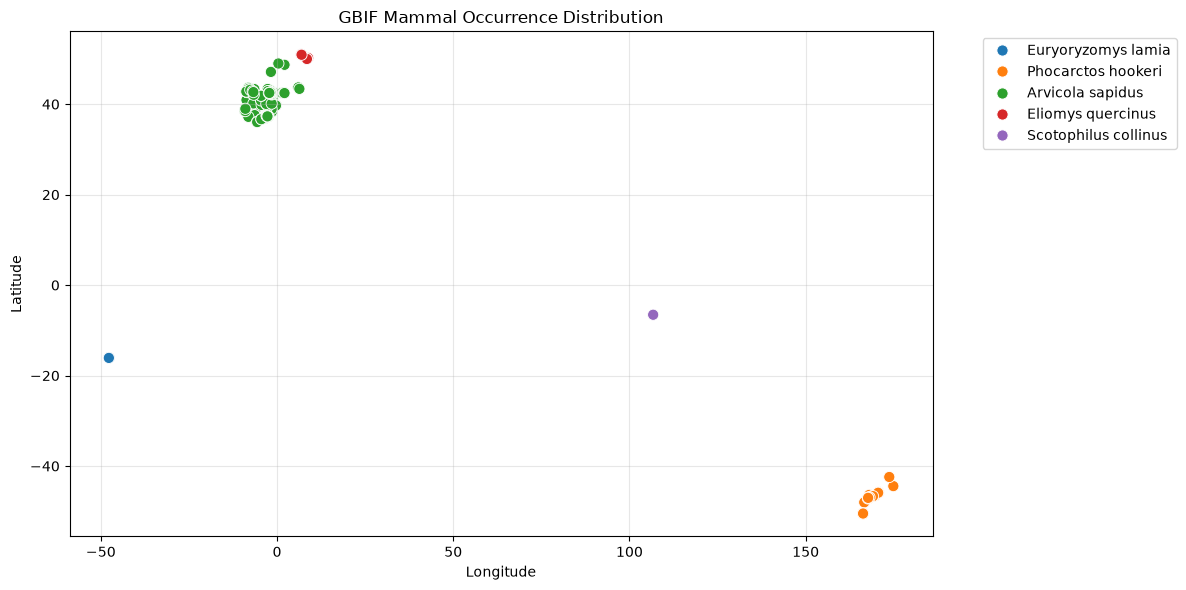

In [27]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=valid_coordinates,
    x="longitude",
    y="latitude",
    hue="scientific_name",
    s=65
)

plt.title("GBIF Mammal Occurrence Distribution")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [28]:
VALIDATED_PATH = GBIF_DIR / "gbif_mammals_validated.csv"

valid_coordinates.to_csv(VALIDATED_PATH, index=False)

print("Validated dataset saved:", VALIDATED_PATH)
print("Total valid records:", len(valid_coordinates))
print("Species represented:", valid_coordinates["scientific_name"].nunique())

Validated dataset saved: D:\wildlife\datasets\gbif\gbif_mammals_validated.csv
Total valid records: 305
Species represented: 5


In [29]:
print("Records per species:")
display(valid_coordinates["scientific_name"].value_counts())

print("\nCoordinate uncertainty:")
display(valid_coordinates["coordinate_uncertainty"].describe())

print("\nMissing coordinate uncertainty:")
print(valid_coordinates["coordinate_uncertainty"].isna().sum())

Records per species:


scientific_name
Phocarctos hookeri      100
Arvicola sapidus        100
Eliomys quercinus       100
Euryoryzomys lamia        4
Scotophilus collinus      1
Name: count, dtype: int64


Coordinate uncertainty:


count       284.000000
mean       4207.704225
std       29928.014940
min           1.000000
25%           8.000000
50%         250.000000
75%         250.000000
max      489734.000000
Name: coordinate_uncertainty, dtype: float64


Missing coordinate uncertainty:
21


In [30]:
# Create a quality-controlled copy of GBIF records

gbif_quality = valid_coordinates.copy()

# Flag records with acceptable coordinate uncertainty
# 10 km is our initial quality threshold
gbif_quality["coordinate_quality"] = (
    gbif_quality["coordinate_uncertainty"].notna()
    & (gbif_quality["coordinate_uncertainty"] <= 10000)
)

print("Total records:", len(gbif_quality))

print("\nCoordinate quality:")
print(gbif_quality["coordinate_quality"].value_counts())

print("\nRecords per species and quality:")
display(
    gbif_quality.groupby(
        ["scientific_name", "coordinate_quality"]
    ).size().unstack(fill_value=0)
)

Total records: 305

Coordinate quality:
coordinate_quality
True     260
False     45
Name: count, dtype: int64

Records per species and quality:


coordinate_quality,False,True
scientific_name,,
Arvicola sapidus,28,72
Eliomys quercinus,0,100
Euryoryzomys lamia,4,0
Phocarctos hookeri,13,87
Scotophilus collinus,0,1


In [31]:
import pandas as pd
from pathlib import Path

# Define project paths
PROJECT_DIR = Path(r"D:\wildlife")
IUCN_PATH = PROJECT_DIR / "datasets" / "iucn" / "iucn_mammals_cleaned.csv"
GBIF_DIR = PROJECT_DIR / "datasets" / "gbif"

# Load cleaned IUCN dataset
iucn_clean = pd.read_csv(IUCN_PATH)

# Select 50 species from each risk class
threatened_sample = (
    iucn_clean[iucn_clean["risk_target"] == 1]
    .sample(n=50, random_state=42)
)

non_threatened_sample = (
    iucn_clean[iucn_clean["risk_target"] == 0]
    .sample(n=50, random_state=42)
)

# Combine and shuffle
species_sample = pd.concat(
    [threatened_sample, non_threatened_sample]
).sample(frac=1, random_state=42).reset_index(drop=True)

# Save development sample
SAMPLE_PATH = GBIF_DIR / "iucn_species_development_sample.csv"
species_sample.to_csv(SAMPLE_PATH, index=False)

print("Development sample created!")
print("Total species:", len(species_sample))
print("\nRisk distribution:")
print(species_sample["risk_target"].value_counts())
print("\nSaved to:", SAMPLE_PATH)

display(
    species_sample[
        ["species_id", "scientific_name", "category", "risk_target"]
    ].head(10)
)

Development sample created!
Total species: 100

Risk distribution:
risk_target
0    50
1    50
Name: count, dtype: int64

Saved to: D:\wildlife\datasets\gbif\iucn_species_development_sample.csv


,species_id,scientific_name,category,risk_target
0,42679,Petrodromus tetradactylus,LC,0
1,218360290,Nyctophilus holtorum,LC,0
2,81633156,Miniopterus maghrebensis,NT,0
3,11496,Lemur catta,EN,1
4,6676,Dipodomys gravipes,CR,1
5,39803,Presbytis chrysomelas,CR,1
6,39916,Alouatta guariba,VU,1
7,13161,Meriones crassus,LC,0
8,13217,Mesocapromys nanus,CR,1
9,12828,Marmota vancouverensis,CR,1


In [32]:
import requests
import pandas as pd
import time
from pathlib import Path

# Paths
GBIF_DIR = Path(r"D:\wildlife\datasets\gbif")
SAMPLE_PATH = GBIF_DIR / "iucn_species_development_sample.csv"
MATCH_PATH = GBIF_DIR / "gbif_species_matches_100.csv"

# Load development sample
species_sample = pd.read_csv(SAMPLE_PATH)

# Resume from existing results if the file exists
if MATCH_PATH.exists():
    match_results = pd.read_csv(MATCH_PATH).to_dict("records")
    completed_names = {
        row["requested_name"] for row in match_results
    }
else:
    match_results = []
    completed_names = set()

session = requests.Session()
session.headers.update({
    "User-Agent": "WildlifeSpeciesRiskAssessment/1.0"
})

BASE_URL = "https://api.gbif.org/v1/species/match"

print("Starting GBIF taxonomy matching...")
print("Already completed:", len(completed_names))

for _, row in species_sample.iterrows():

    name = row["scientific_name"]

    if name in completed_names:
        continue

    print(f"\nMatching: {name}")

    result = {
        "requested_name": name,
        "species_id": row["species_id"],
        "risk_target": row["risk_target"],
        "category": row["category"],
        "gbif_name": None,
        "taxon_key": None,
        "match_type": None,
        "rank": None,
        "status": None,
        "confidence": None,
        "success": False,
        "error": None
    }

    for attempt in range(3):
        try:
            response = session.get(
                BASE_URL,
                params={"name": name},
                timeout=(10, 30)
            )
            response.raise_for_status()

            data = response.json()

            result.update({
                "gbif_name": data.get("scientificName"),
                "taxon_key": data.get("speciesKey"),
                "match_type": data.get("matchType"),
                "rank": data.get("rank"),
                "status": data.get("status"),
                "confidence": data.get("confidence")
            })

            result["success"] = (
                data.get("matchType") == "EXACT"
                and data.get("rank") == "SPECIES"
                and data.get("status") == "ACCEPTED"
                and data.get("speciesKey") is not None
            )

            break

        except requests.RequestException as error:
            result["error"] = str(error)
            print(f"Attempt {attempt + 1} failed: {error}")
            time.sleep(2 ** attempt)

    match_results.append(result)

    # Save after every species
    pd.DataFrame(match_results).to_csv(
        MATCH_PATH,
        index=False
    )

    print("Accepted exact match:", result["success"])
    time.sleep(0.2)

# Final summary
matches_df = pd.DataFrame(match_results)

print("\nMatching completed!")
print("Total processed:", len(matches_df))
print("Accepted exact matches:", matches_df["success"].sum())
print("Unmatched or non-exact:", (~matches_df["success"]).sum())

print("\nResults by risk class:")
display(
    matches_df.groupby("risk_target")["success"]
    .agg(["count", "sum"])
)

print("\nSaved at:", MATCH_PATH)

display(matches_df.head(15))

Starting GBIF taxonomy matching...
Already completed: 0

Matching: Petrodromus tetradactylus
Accepted exact match: True

Matching: Nyctophilus holtorum
Accepted exact match: True

Matching: Miniopterus maghrebensis
Accepted exact match: True

Matching: Lemur catta
Accepted exact match: True

Matching: Dipodomys gravipes
Accepted exact match: True

Matching: Presbytis chrysomelas
Accepted exact match: True

Matching: Alouatta guariba
Accepted exact match: True

Matching: Meriones crassus
Accepted exact match: True

Matching: Mesocapromys nanus
Accepted exact match: True

Matching: Marmota vancouverensis
Accepted exact match: True

Matching: Eulemur rufus
Accepted exact match: True

Matching: Neofelis nebulosa
Accepted exact match: True

Matching: Reithrodon typicus
Accepted exact match: True

Matching: Lagothrix flavicauda
Accepted exact match: True

Matching: Perameles nasuta
Accepted exact match: True

Matching: Eonycteris robusta
Accepted exact match: True

Matching: Notiosorex evoti

,count,sum
risk_target,,
0,50,45
1,50,46



Saved at: D:\wildlife\datasets\gbif\gbif_species_matches_100.csv


,requested_name,species_id,risk_target,category,gbif_name,taxon_key,match_type,rank,status,confidence,success,error
0,Petrodromus tetradactylus,42679,0,LC,"Petrodromus tetradactylus Peters, 1846",2440858.0,EXACT,SPECIES,ACCEPTED,99,True,None
1,Nyctophilus holtorum,218360290,0,LC,"Nyctophilus holtorum Parnaby, King & Eldridge,...",11199407.0,EXACT,SPECIES,ACCEPTED,99,True,None
2,Miniopterus maghrebensis,81633156,0,NT,"Miniopterus maghrebensis Puechmaille, Allegrin...",8126077.0,EXACT,SPECIES,ACCEPTED,99,True,None
3,Lemur catta,11496,1,EN,"Lemur catta Linnaeus, 1758",2436412.0,EXACT,SPECIES,ACCEPTED,99,True,None
4,Dipodomys gravipes,6676,1,CR,"Dipodomys gravipes Huey, 1925",2439544.0,EXACT,SPECIES,ACCEPTED,99,True,None
5,Presbytis chrysomelas,39803,1,CR,"Presbytis chrysomelas (Müller, 1838)",7262008.0,EXACT,SPECIES,ACCEPTED,99,True,None
6,Alouatta guariba,39916,1,VU,"Alouatta guariba (Humboldt, 1812)",7262055.0,EXACT,SPECIES,ACCEPTED,99,True,None
7,Meriones crassus,13161,0,LC,"Meriones crassus Sundevall, 1842",5219724.0,EXACT,SPECIES,ACCEPTED,99,True,None
8,Mesocapromys nanus,13217,1,CR,"Mesocapromys nanus (G.M.Allen, 1917)",2437642.0,EXACT,SPECIES,ACCEPTED,99,True,None
9,Marmota vancouverensis,12828,1,CR,"Marmota vancouverensis Swarth, 1911",2437365.0,EXACT,SPECIES,ACCEPTED,99,True,None


In [33]:
import requests
import pandas as pd
import time
from pathlib import Path

# Paths
GBIF_DIR = Path(r"D:\wildlife\datasets\gbif")
SAMPLE_PATH = GBIF_DIR / "iucn_species_development_sample.csv"
MATCH_PATH = GBIF_DIR / "gbif_species_matches_100.csv"

# Load development sample
species_sample = pd.read_csv(SAMPLE_PATH)

# Resume from existing results if the file exists
if MATCH_PATH.exists():
    match_results = pd.read_csv(MATCH_PATH).to_dict("records")
    completed_names = {
        row["requested_name"] for row in match_results
    }
else:
    match_results = []
    completed_names = set()

session = requests.Session()
session.headers.update({
    "User-Agent": "WildlifeSpeciesRiskAssessment/1.0"
})

BASE_URL = "https://api.gbif.org/v1/species/match"

print("Starting GBIF taxonomy matching...")
print("Already completed:", len(completed_names))

for _, row in species_sample.iterrows():

    name = row["scientific_name"]

    if name in completed_names:
        continue

    print(f"\nMatching: {name}")

    result = {
        "requested_name": name,
        "species_id": row["species_id"],
        "risk_target": row["risk_target"],
        "category": row["category"],
        "gbif_name": None,
        "taxon_key": None,
        "match_type": None,
        "rank": None,
        "status": None,
        "confidence": None,
        "success": False,
        "error": None
    }

    for attempt in range(3):
        try:
            response = session.get(
                BASE_URL,
                params={"name": name},
                timeout=(10, 30)
            )
            response.raise_for_status()

            data = response.json()

            result.update({
                "gbif_name": data.get("scientificName"),
                "taxon_key": data.get("speciesKey"),
                "match_type": data.get("matchType"),
                "rank": data.get("rank"),
                "status": data.get("status"),
                "confidence": data.get("confidence")
            })

            result["success"] = (
                data.get("matchType") == "EXACT"
                and data.get("rank") == "SPECIES"
                and data.get("status") == "ACCEPTED"
                and data.get("speciesKey") is not None
            )

            break

        except requests.RequestException as error:
            result["error"] = str(error)
            print(f"Attempt {attempt + 1} failed: {error}")
            time.sleep(2 ** attempt)

    match_results.append(result)

    # Save after every species
    pd.DataFrame(match_results).to_csv(
        MATCH_PATH,
        index=False
    )

    print("Accepted exact match:", result["success"])
    time.sleep(0.2)

# Final summary
matches_df = pd.DataFrame(match_results)

print("\nMatching completed!")
print("Total processed:", len(matches_df))
print("Accepted exact matches:", matches_df["success"].sum())
print("Unmatched or non-exact:", (~matches_df["success"]).sum())

print("\nResults by risk class:")
display(
    matches_df.groupby("risk_target")["success"]
    .agg(["count", "sum"])
)

print("\nSaved at:", MATCH_PATH)

display(matches_df.head(15))

Starting GBIF taxonomy matching...
Already completed: 100

Matching completed!
Total processed: 100
Accepted exact matches: 91
Unmatched or non-exact: 9

Results by risk class:


,count,sum
risk_target,,
0,50,45
1,50,46



Saved at: D:\wildlife\datasets\gbif\gbif_species_matches_100.csv


,requested_name,species_id,risk_target,category,gbif_name,taxon_key,match_type,rank,status,confidence,success,error
0,Petrodromus tetradactylus,42679,0,LC,"Petrodromus tetradactylus Peters, 1846",2440858.0,EXACT,SPECIES,ACCEPTED,99,True,NaN
1,Nyctophilus holtorum,218360290,0,LC,"Nyctophilus holtorum Parnaby, King & Eldridge,...",11199407.0,EXACT,SPECIES,ACCEPTED,99,True,NaN
2,Miniopterus maghrebensis,81633156,0,NT,"Miniopterus maghrebensis Puechmaille, Allegrin...",8126077.0,EXACT,SPECIES,ACCEPTED,99,True,NaN
3,Lemur catta,11496,1,EN,"Lemur catta Linnaeus, 1758",2436412.0,EXACT,SPECIES,ACCEPTED,99,True,NaN
4,Dipodomys gravipes,6676,1,CR,"Dipodomys gravipes Huey, 1925",2439544.0,EXACT,SPECIES,ACCEPTED,99,True,NaN
5,Presbytis chrysomelas,39803,1,CR,"Presbytis chrysomelas (Müller, 1838)",7262008.0,EXACT,SPECIES,ACCEPTED,99,True,NaN
6,Alouatta guariba,39916,1,VU,"Alouatta guariba (Humboldt, 1812)",7262055.0,EXACT,SPECIES,ACCEPTED,99,True,NaN
7,Meriones crassus,13161,0,LC,"Meriones crassus Sundevall, 1842",5219724.0,EXACT,SPECIES,ACCEPTED,99,True,NaN
8,Mesocapromys nanus,13217,1,CR,"Mesocapromys nanus (G.M.Allen, 1917)",2437642.0,EXACT,SPECIES,ACCEPTED,99,True,NaN
9,Marmota vancouverensis,12828,1,CR,"Marmota vancouverensis Swarth, 1911",2437365.0,EXACT,SPECIES,ACCEPTED,99,True,NaN


In [34]:
# Inspect all unsuccessful GBIF matches

failed_matches = matches_df[
    matches_df["success"].fillna(False) == False
].copy()

print("Unsuccessful species:", len(failed_matches))

display(
    failed_matches[
        [
            "requested_name",
            "gbif_name",
            "taxon_key",
            "match_type",
            "rank",
            "status",
            "confidence",
            "error"
        ]
    ]
)

Unsuccessful species: 9


,requested_name,gbif_name,taxon_key,match_type,rank,status,confidence,error
18,Mops johorensis,"Mops Lesson, 1842",NaN,HIGHERRANK,GENUS,ACCEPTED,92,NaN
20,Heteromys adspersus,"Heteromys adspersus (Peters, 1874)",2439505.0,EXACT,SPECIES,SYNONYM,98,NaN
31,Pseudocheirus occidentalis,"Pseudocheirus occidentalis (Thomas, 1888)",2440062.0,EXACT,SPECIES,SYNONYM,98,NaN
35,Porcula salvania,"Porcula salvania Hodgson, 1847",2441220.0,EXACT,SPECIES,SYNONYM,98,NaN
41,Bradypus crinitus,"Bradypus crinitus Gray, 1850",2436351.0,EXACT,SPECIES,SYNONYM,98,NaN
46,Myotis aurascens,"Myotis aurascens Kuzyakin, 1935",4266349.0,EXACT,SPECIES,SYNONYM,98,NaN
55,Erethizon dorsatum,"Erethizon dorsatus (Linnaeus, 1758)",6066824.0,FUZZY,SPECIES,ACCEPTED,96,NaN
78,Platyrrhinus nigellus,"Platyrrhinus nigellus (Gardner & Carter, 1972)",5218768.0,EXACT,SPECIES,SYNONYM,98,NaN
89,Lophostoma silvicolum,"Lophostoma silvicola d'Orbigny, 1836",5706810.0,FUZZY,SPECIES,ACCEPTED,96,NaN


In [35]:
import requests
import pandas as pd
import time

session = requests.Session()
session.headers.update({
    "User-Agent": "WildlifeSpeciesRiskAssessment/1.0"
})

failed_matches = matches_df[
    matches_df["success"].fillna(False) == False
].copy()

resolution_results = []

for _, row in failed_matches.iterrows():

    key = row["taxon_key"]

    result = {
        "requested_name": row["requested_name"],
        "original_gbif_name": row["gbif_name"],
        "original_match_type": row["match_type"],
        "original_status": row["status"],
        "returned_taxon_key": key,
        "accepted_key": None,
        "accepted_name": None,
        "accepted_status": None,
        "rank": row["rank"]
    }

    if pd.notna(key):

        try:
            response = session.get(
                f"https://api.gbif.org/v1/species/{int(key)}",
                timeout=(10, 30)
            )
            response.raise_for_status()
            data = response.json()

            accepted_key = data.get("acceptedKey")

            result["accepted_key"] = accepted_key
            result["accepted_status"] = data.get("taxonomicStatus")
            result["rank"] = data.get("rank")

            if accepted_key:
                accepted_response = session.get(
                    f"https://api.gbif.org/v1/species/{int(accepted_key)}",
                    timeout=(10, 30)
                )
                accepted_response.raise_for_status()
                accepted_data = accepted_response.json()

                result["accepted_name"] = (
                    accepted_data.get("scientificName")
                )

            elif data.get("taxonomicStatus") == "ACCEPTED":
                result["accepted_key"] = data.get("key")
                result["accepted_name"] = data.get("scientificName")

        except requests.RequestException as error:
            result["accepted_name"] = f"API ERROR: {error}"

    resolution_results.append(result)
    time.sleep(0.2)

resolution_df = pd.DataFrame(resolution_results)

display(resolution_df)

RESOLUTION_PATH = GBIF_DIR / "gbif_taxonomy_resolution.csv"
resolution_df.to_csv(RESOLUTION_PATH, index=False)

print("\nSaved:", RESOLUTION_PATH)

,requested_name,original_gbif_name,original_match_type,original_status,returned_taxon_key,accepted_key,accepted_name,accepted_status,rank
0,Mops johorensis,"Mops Lesson, 1842",HIGHERRANK,ACCEPTED,NaN,NaN,NaN,NaN,GENUS
1,Heteromys adspersus,"Heteromys adspersus (Peters, 1874)",EXACT,SYNONYM,2439505.0,2439505.0,"Liomys adspersus (Peters, 1874)",ACCEPTED,SPECIES
2,Pseudocheirus occidentalis,"Pseudocheirus occidentalis (Thomas, 1888)",EXACT,SYNONYM,2440062.0,2440062.0,"Pseudocheirus peregrinus (Boddaert, 1785)",ACCEPTED,SPECIES
3,Porcula salvania,"Porcula salvania Hodgson, 1847",EXACT,SYNONYM,2441220.0,2441220.0,"Sus salvanius (Hodgson, 1847)",ACCEPTED,SPECIES
4,Bradypus crinitus,"Bradypus crinitus Gray, 1850",EXACT,SYNONYM,2436351.0,2436351.0,"Bradypus torquatus Illiger, 1811",ACCEPTED,SPECIES
5,Myotis aurascens,"Myotis aurascens Kuzyakin, 1935",EXACT,SYNONYM,4266349.0,4266349.0,"Myotis davidii (Peters, 1869)",ACCEPTED,SPECIES
6,Erethizon dorsatum,"Erethizon dorsatus (Linnaeus, 1758)",FUZZY,ACCEPTED,6066824.0,6066824.0,"Erethizon dorsatus (Linnaeus, 1758)",ACCEPTED,SPECIES
7,Platyrrhinus nigellus,"Platyrrhinus nigellus (Gardner & Carter, 1972)",EXACT,SYNONYM,5218768.0,5218768.0,"Platyrrhinus umbratus (Lyon, 1902)",ACCEPTED,SPECIES
8,Lophostoma silvicolum,"Lophostoma silvicola d'Orbigny, 1836",FUZZY,ACCEPTED,5706810.0,5706810.0,"Lophostoma silvicola d'Orbigny, 1836",ACCEPTED,SPECIES



Saved: D:\wildlife\datasets\gbif\gbif_taxonomy_resolution.csv


In [36]:
# Keep only verified exact GBIF species matches

verified_matches = matches_df[
    matches_df["success"].fillna(False)
    & (matches_df["match_type"] == "EXACT")
    & (matches_df["rank"] == "SPECIES")
].copy()

# Convert GBIF taxon keys to integers
verified_matches["taxon_key"] = (
    verified_matches["taxon_key"].astype("int64")
)

# Save verified list
VERIFIED_PATH = GBIF_DIR / "gbif_verified_species_91.csv"

verified_matches.to_csv(VERIFIED_PATH, index=False)

print("Verified species:", len(verified_matches))
print("\nRisk distribution:")
print(verified_matches["risk_target"].value_counts())

print("\nSaved:", VERIFIED_PATH)

display(
    verified_matches[
        ["requested_name", "taxon_key", "category", "risk_target"]
    ].head()
)

Verified species: 91

Risk distribution:
risk_target
1    46
0    45
Name: count, dtype: int64

Saved: D:\wildlife\datasets\gbif\gbif_verified_species_91.csv


,requested_name,taxon_key,category,risk_target
0,Petrodromus tetradactylus,2440858,LC,0
1,Nyctophilus holtorum,11199407,LC,0
2,Miniopterus maghrebensis,8126077,NT,0
3,Lemur catta,2436412,EN,1
4,Dipodomys gravipes,2439544,CR,1


In [37]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(r"D:\wildlife")
GBIF_DIR = PROJECT_DIR / "datasets" / "gbif"

VERIFIED_PATH = GBIF_DIR / "gbif_verified_species_91.csv"

verified_matches = pd.read_csv(VERIFIED_PATH)

print("Verified species:", len(verified_matches))
print("Unique GBIF keys:", verified_matches["taxon_key"].nunique())
print("\nRisk distribution:")
print(verified_matches["risk_target"].value_counts())

assert len(verified_matches) == 91
assert verified_matches["taxon_key"].notna().all()

print("\nReady for occurrence collection!")

Verified species: 91
Unique GBIF keys: 91

Risk distribution:
risk_target
1    46
0    45
Name: count, dtype: int64

Ready for occurrence collection!


In [38]:
import requests
import pandas as pd
import time
from pathlib import Path

# Paths
PROJECT_DIR = Path(r"D:\wildlife")
GBIF_DIR = PROJECT_DIR / "datasets" / "gbif"
GBIF_DIR.mkdir(parents=True, exist_ok=True)

VERIFIED_PATH = GBIF_DIR / "gbif_verified_species_91.csv"
OUTPUT_PATH = GBIF_DIR / "gbif_occurrences_91_species.csv"

verified_matches = pd.read_csv(VERIFIED_PATH)

# Download settings
MAX_RECORDS_PER_SPECIES = 100
GBIF_URL = "https://api.gbif.org/v1/occurrence/search"

# Fields to retain
FIELDS = [
    "gbifID",
    "taxonKey",
    "scientificName",
    "decimalLatitude",
    "decimalLongitude",
    "coordinateUncertaintyInMeters",
    "year",
    "eventDate",
    "basisOfRecord",
    "countryCode",
    "datasetKey",
    "occurrenceID"
]

# Load existing checkpoint, if present
if OUTPUT_PATH.exists():
    all_records = pd.read_csv(OUTPUT_PATH)
    completed_keys = set(all_records["taxonKey"].dropna().astype(int))
    print(f"Resuming: {len(completed_keys)} species already processed.")
else:
    all_records = pd.DataFrame()
    completed_keys = set()
    print("Starting a fresh download.")

session = requests.Session()
session.headers.update({"User-Agent": "WildlifeSpeciesRiskAssessment/1.0"})

failed_species = []

for index, species in verified_matches.iterrows():

    taxon_key = int(species["taxon_key"])

    if taxon_key in completed_keys:
        continue

    requested_name = species["requested_name"]
    risk_target = int(species["risk_target"])
    species_id = species["species_id"]
    gbif_name = species["gbif_name"]

    params = {
        "taxonKey": taxon_key,
        "hasCoordinate": "true",
        "hasGeospatialIssue": "false",
        "occurrenceStatus": "PRESENT",
        "limit": MAX_RECORDS_PER_SPECIES,
        "offset": 0
    }

    records = None

    for attempt in range(1, 4):
        try:
            response = session.get(
                GBIF_URL,
                params=params,
                timeout=(15, 60)
            )
            response.raise_for_status()
            records = response.json().get("results", [])
            break

        except requests.RequestException as error:
            print(
                f"Retry {attempt}/3 for {requested_name}: {error}"
            )
            time.sleep(2 * attempt)

    if records is None:
        failed_species.append(requested_name)
        print(f"FAILED: {requested_name}")
        continue

    species_records = []

    for record in records:
        row = {field: record.get(field) for field in FIELDS}
        row["requested_name"] = requested_name
        row["species_id"] = species_id
        row["risk_target"] = risk_target
        species_records.append(row)

    if species_records:
        new_df = pd.DataFrame(species_records)
        all_records = pd.concat(
            [all_records, new_df],
            ignore_index=True
        )

    # Save checkpoint after every species
    all_records.to_csv(OUTPUT_PATH, index=False)
    completed_keys.add(taxon_key)

    print(
        f"[{len(completed_keys)}/91] "
        f"{requested_name}: {len(records)} records"
    )

    time.sleep(0.3)

print("\nDOWNLOAD SUMMARY")
print("Species processed:", len(completed_keys))
print("Occurrence records:", len(all_records))
print("Species with failed requests:", len(failed_species))
print("Saved to:", OUTPUT_PATH)

if failed_species:
    print("\nFailed species:")
    print(failed_species)

Starting a fresh download.
Retry 1/3 for Petrodromus tetradactylus: HTTPSConnectionPool(host='api.gbif.org', port=443): Read timed out.
Retry 2/3 for Petrodromus tetradactylus: HTTPSConnectionPool(host='api.gbif.org', port=443): Read timed out.
[1/91] Petrodromus tetradactylus: 100 records
Retry 1/3 for Nyctophilus holtorum: HTTPSConnectionPool(host='api.gbif.org', port=443): Read timed out. (read timeout=15)
[2/91] Nyctophilus holtorum: 88 records
[3/91] Miniopterus maghrebensis: 22 records
[4/91] Lemur catta: 100 records
[5/91] Dipodomys gravipes: 100 records
[6/91] Presbytis chrysomelas: 41 records
[7/91] Alouatta guariba: 100 records
[8/91] Meriones crassus: 100 records
Retry 1/3 for Mesocapromys nanus: HTTPSConnectionPool(host='api.gbif.org', port=443): Read timed out.
[9/91] Mesocapromys nanus: 23 records
[10/91] Marmota vancouverensis: 100 records
[11/91] Eulemur rufus: 77 records
[12/91] Neofelis nebulosa: 100 records
[13/91] Reithrodon typicus: 13 records
[14/91] Lagothrix fla

In [39]:
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_DIR = Path(r"D:\wildlife")
GBIF_DIR = PROJECT_DIR / "datasets" / "gbif"

INPUT_PATH = GBIF_DIR / "gbif_occurrences_91_species.csv"
OUTPUT_PATH = GBIF_DIR / "gbif_occurrences_cleaned.csv"

occ = pd.read_csv(INPUT_PATH)

# Convert coordinates and uncertainty to numeric
occ["decimalLatitude"] = pd.to_numeric(
    occ["decimalLatitude"], errors="coerce"
)
occ["decimalLongitude"] = pd.to_numeric(
    occ["decimalLongitude"], errors="coerce"
)
occ["coordinateUncertaintyInMeters"] = pd.to_numeric(
    occ["coordinateUncertaintyInMeters"], errors="coerce"
)

# Remove missing or geographically invalid coordinates
occ = occ.dropna(
    subset=["decimalLatitude", "decimalLongitude"]
).copy()

occ = occ[
    occ["decimalLatitude"].between(-90, 90)
    & occ["decimalLongitude"].between(-180, 180)
].copy()

# Remove duplicate GBIF records
occ = occ.drop_duplicates(subset=["gbifID"])

# Flag records with coordinate uncertainty <= 10 km
occ["coordinate_quality"] = (
    occ["coordinateUncertaintyInMeters"].le(10000)
)

# Save cleaned data
occ.to_csv(OUTPUT_PATH, index=False)

# Summary
print("CLEANING SUMMARY")
print("Valid occurrence records:", len(occ))
print("Unique species:", occ["taxonKey"].nunique())
print("Unique GBIF records:", occ["gbifID"].nunique())
print("Records with uncertainty <= 10 km:",
      occ["coordinate_quality"].sum())
print("Records with missing uncertainty:",
      occ["coordinateUncertaintyInMeters"].isna().sum())

print("\nRecords per species:")
print(occ.groupby("requested_name").size().describe())

print("\nSaved:", OUTPUT_PATH)

CLEANING SUMMARY
Valid occurrence records: 5892
Unique species: 147
Unique GBIF records: 5892
Records with uncertainty <= 10 km: 2229
Records with missing uncertainty: 2375

Records per species:
count     88.000000
mean      66.954545
std       39.912522
min        1.000000
25%       21.750000
50%      100.000000
75%      100.000000
max      100.000000
dtype: float64

Saved: D:\wildlife\datasets\gbif\gbif_occurrences_cleaned.csv


In [40]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(r"D:\wildlife")
GBIF_DIR = PROJECT_DIR / "datasets" / "gbif"

occ = pd.read_csv(GBIF_DIR / "gbif_occurrences_cleaned.csv")
species = pd.read_csv(GBIF_DIR / "gbif_verified_species_91.csv")

summary = (
    occ.groupby("species_id")
    .agg(
        occurrence_count=("gbifID", "nunique"),
        high_quality_count=("coordinate_quality", "sum"),
        median_latitude=("decimalLatitude", "median"),
        median_longitude=("decimalLongitude", "median"),
        median_uncertainty_m=("coordinateUncertaintyInMeters", "median")
    )
    .reset_index()
)

species_summary = species.merge(
    summary,
    on="species_id",
    how="left"
)

species_summary["occurrence_count"] = (
    species_summary["occurrence_count"].fillna(0).astype(int)
)

species_summary["high_quality_count"] = (
    species_summary["high_quality_count"].fillna(0).astype(int)
)

OUTPUT_PATH = GBIF_DIR / "species_occurrence_summary_91.csv"
species_summary.to_csv(OUTPUT_PATH, index=False)

print("Species in master table:", len(species_summary))
print("Species with occurrences:",
      (species_summary["occurrence_count"] > 0).sum())
print("Species without occurrences:",
      (species_summary["occurrence_count"] == 0).sum())
print("Total occurrences:", species_summary["occurrence_count"].sum())

print("\nRisk distribution:")
print(species_summary.groupby("risk_target")["occurrence_count"].agg(
    ["count", "mean", "median", "sum"]
))

print("\nSaved:", OUTPUT_PATH)

Species in master table: 91
Species with occurrences: 88
Species without occurrences: 3
Total occurrences: 5892

Risk distribution:
             count       mean  median   sum
risk_target                                
0               45  75.333333   100.0  3390
1               46  54.391304    44.0  2502

Saved: D:\wildlife\datasets\gbif\species_occurrence_summary_91.csv


In [41]:
import requests
import zipfile
from pathlib import Path
import time

PROJECT_DIR = Path(r"D:\wildlife")
WORLDCLIM_DIR = PROJECT_DIR / "datasets" / "worldclim"
WORLDCLIM_DIR.mkdir(parents=True, exist_ok=True)

ZIP_PATH = WORLDCLIM_DIR / "wc2.1_10m_bio.zip"

URL = (
    "https://geodata.ucdavis.edu/climate/"
    "worldclim/2_1/base/wc2.1_10m_bio.zip"
)

# Download only if not already downloaded
if not ZIP_PATH.exists() or ZIP_PATH.stat().st_size == 0:

    for attempt in range(1, 4):
        try:
            print(f"Downloading WorldClim (attempt {attempt}/3)...")

            response = requests.get(
                URL,
                stream=True,
                timeout=(30, 180)
            )
            response.raise_for_status()

            total = int(response.headers.get("content-length", 0))
            downloaded = 0

            with open(ZIP_PATH, "wb") as file:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        file.write(chunk)
                        downloaded += len(chunk)

                        if total:
                            print(
                                f"\rDownloaded: "
                                f"{downloaded / total * 100:.1f}%",
                                end=""
                            )

            print("\nDownload complete!")
            break

        except Exception as error:
            print(f"\nDownload error: {error}")

            if ZIP_PATH.exists():
                ZIP_PATH.unlink()

            if attempt == 3:
                raise

            time.sleep(3)

else:
    print("WorldClim ZIP already exists. Skipping download.")

# Extract GeoTIFF files
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    archive.extractall(WORLDCLIM_DIR)

tif_files = list(WORLDCLIM_DIR.glob("*.tif"))

print("\nWorldClim extraction complete.")
print("GeoTIFF files found:", len(tif_files))
print("Folder:", WORLDCLIM_DIR)

print("\nSample files:")
for file in tif_files[:8]:
    print(file.name)

Downloaded: 100.0%
Download complete!

WorldClim extraction complete.
GeoTIFF files found: 19
Folder: D:\wildlife\datasets\worldclim

Sample files:
wc2.1_10m_bio_1.tif
wc2.1_10m_bio_10.tif
wc2.1_10m_bio_11.tif
wc2.1_10m_bio_12.tif
wc2.1_10m_bio_13.tif
wc2.1_10m_bio_14.tif
wc2.1_10m_bio_15.tif
wc2.1_10m_bio_16.tif


In [44]:
import pandas as pd
import numpy as np
import rasterio
from pathlib import Path

PROJECT_DIR = Path(r"D:\wildlife")
GBIF_DIR = PROJECT_DIR / "datasets" / "gbif"
WORLDCLIM_DIR = PROJECT_DIR / "datasets" / "worldclim"

occ = pd.read_csv(GBIF_DIR / "gbif_occurrences_cleaned.csv")

# Selected WorldClim variables
BIO_VARIABLES = [1, 4, 5, 6, 12, 15]

# Extract climate values at each occurrence coordinate
for bio in BIO_VARIABLES:

    raster_path = WORLDCLIM_DIR / f"wc2.1_10m_bio_{bio}.tif"

    print(f"Extracting BIO{bio}...")

    with rasterio.open(raster_path) as src:

        coordinates = list(zip(
            occ["decimalLongitude"],
            occ["decimalLatitude"]
        ))

        values = [
            result[0] if result[0] is not None else np.nan
            for result in src.sample(coordinates)
        ]

        # Handle raster NoData values
        values = [
            np.nan if value == src.nodata else value
            for value in values
        ]

        occ[f"BIO{bio}"] = values

# Save occurrence-level climate data
occurrence_output = GBIF_DIR / "gbif_occurrences_with_climate.csv"
occ.to_csv(occurrence_output, index=False)

# Aggregate climate values by requested species
climate_columns = [f"BIO{bio}" for bio in BIO_VARIABLES]

species_climate = (
    occ.groupby("species_id")[climate_columns]
    .median()
    .reset_index()
)

# Add species names and target labels
species = pd.read_csv(
    GBIF_DIR / "gbif_verified_species_91.csv"
)

model_data = species[
    ["species_id", "requested_name", "risk_target", "category"]
].merge(
    species_climate,
    on="species_id",
    how="left"
)

model_output = GBIF_DIR / "wildlife_species_climate_dataset.csv"
model_data.to_csv(model_output, index=False)

print("\nCLIMATE EXTRACTION SUMMARY")
print("Occurrence records:", len(occ))
print("Species in model dataset:", len(model_data))
print("Climate variables:", climate_columns)

print("\nMissing values:")
print(model_data[climate_columns].isna().sum())

print("\nFinal dataset shape:", model_data.shape)
print("\nSaved:", model_output)

Extracting BIO1...
Extracting BIO4...
Extracting BIO5...
Extracting BIO6...
Extracting BIO12...
Extracting BIO15...

CLIMATE EXTRACTION SUMMARY
Occurrence records: 5892
Species in model dataset: 91
Climate variables: ['BIO1', 'BIO4', 'BIO5', 'BIO6', 'BIO12', 'BIO15']

Missing values:
BIO1     4
BIO4     4
BIO5     4
BIO6     4
BIO12    4
BIO15    4
dtype: int64

Final dataset shape: (91, 10)

Saved: D:\wildlife\datasets\gbif\wildlife_species_climate_dataset.csv


In [45]:
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_DIR = Path(r"D:\wildlife")
GBIF_DIR = PROJECT_DIR / "datasets" / "gbif"

INPUT_PATH = GBIF_DIR / "wildlife_species_climate_dataset.csv"

df = pd.read_csv(INPUT_PATH)

climate_cols = ["BIO1", "BIO4", "BIO5", "BIO6", "BIO12", "BIO15"]

# Inspect missing species
missing_rows = df[df[climate_cols].isna().any(axis=1)]

print("Species with missing climate values:")
print(missing_rows[["requested_name", "risk_target"] + climate_cols])

print("\nMissing values per variable:")
print(df[climate_cols].isna().sum())

# Convert scaled variables
for col in ["BIO1", "BIO5", "BIO6"]:
    df[col] = df[col] / 10

df["BIO4"] = df["BIO4"] / 100
df["BIO15"] = df["BIO15"] / 100

# Keep complete cases for the initial modelling dataset
model_df = df.dropna(subset=climate_cols).copy()

# Save both the converted full dataset and complete modelling dataset
df.to_csv(GBIF_DIR / "wildlife_climate_converted_all.csv", index=False)

model_df.to_csv(
    GBIF_DIR / "wildlife_modeling_dataset.csv",
    index=False
)

print("\nMODELLING DATASET SUMMARY")
print("Original species:", len(df))
print("Complete species:", len(model_df))
print("Excluded due to missing climate:", len(df) - len(model_df))

print("\nRisk distribution:")
print(model_df["risk_target"].value_counts())

print("\nClimate variable statistics:")
print(model_df[climate_cols].describe().round(3))

print("\nSaved:", GBIF_DIR / "wildlife_modeling_dataset.csv")

Species with missing climate values:
            requested_name  risk_target  BIO1  BIO4  BIO5  BIO6  BIO12  BIO15
20       Pteropus faunulus            1   NaN   NaN   NaN   NaN    NaN    NaN
45  Rhynchomeles prattorum            1   NaN   NaN   NaN   NaN    NaN    NaN
80      Melomys bannisteri            1   NaN   NaN   NaN   NaN    NaN    NaN
88   Hipposideros demissus            1   NaN   NaN   NaN   NaN    NaN    NaN

Missing values per variable:
BIO1     4
BIO4     4
BIO5     4
BIO6     4
BIO12    4
BIO15    4
dtype: int64

MODELLING DATASET SUMMARY
Original species: 91
Complete species: 87
Excluded due to missing climate: 4

Risk distribution:
risk_target
0    45
1    42
Name: count, dtype: int64

Climate variable statistics:
         BIO1    BIO4    BIO5    BIO6     BIO12   BIO15
count  87.000  87.000  87.000  87.000    87.000  87.000
mean    1.976   2.937   2.876   1.040  1552.994   0.596
std     0.680   2.663   0.487   1.003   928.558   0.269
min    -0.409   0.266   1.345  -

In [53]:
import pandas as pd
import numpy as np
import warnings

from pathlib import Path
from itertools import combinations

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, VotingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import statsmodels.api as sm

warnings.filterwarnings("ignore")

# --------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------

PROJECT_DIR = Path(r"D:\wildlife")
GBIF_DIR = PROJECT_DIR / "datasets" / "gbif"

df = pd.read_csv(
    GBIF_DIR / "wildlife_modeling_dataset.csv"
)

FEATURES = ["BIO1", "BIO4", "BIO5", "BIO6", "BIO12", "BIO15"]
TARGET = "risk_target"

X = df[FEATURES].astype(float)
y = df[TARGET].astype(int)

# --------------------------------------------------
# 2. TRAIN-TEST SPLIT
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("TRAINING DATA:", len(X_train))
print("TEST DATA:", len(X_test))
print("Training class distribution:")
print(y_train.value_counts())

# --------------------------------------------------
# 3. GAM - ADDITIVE SPLINE LOGISTIC MODEL
# --------------------------------------------------

gam_model = Pipeline([
    ("splines", SplineTransformer(
        n_knots=4,
        degree=2,
        include_bias=False
    )),
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

gam_model.fit(X_train, y_train)

gam_prob = gam_model.predict_proba(X_test)[:, 1]
gam_pred = (gam_prob >= 0.5).astype(int)

# --------------------------------------------------
# 4. BMA - BIC-WEIGHTED LOGISTIC MODEL AVERAGING
# --------------------------------------------------

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=FEATURES,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=FEATURES,
    index=X_test.index
)

bma_models = []
bma_bics = []

# Evaluate all non-empty predictor subsets
for size in range(1, len(FEATURES) + 1):

    for subset in combinations(FEATURES, size):

        try:
            train_subset = sm.add_constant(
                X_train_scaled[list(subset)],
                has_constant="add"
            )

            fitted = sm.Logit(
                y_train,
                train_subset
            ).fit(disp=False, maxiter=200)

            if not np.isfinite(fitted.bic):
                continue

            bma_models.append((subset, fitted))
            bma_bics.append(fitted.bic)

        except Exception:
            continue

if len(bma_models) == 0:
    raise RuntimeError("No BMA subset models could be fitted.")

# Calculate normalized BIC weights
bma_bics = np.array(bma_bics)

relative_weights = np.exp(
    -0.5 * (bma_bics - np.min(bma_bics))
)

bma_weights = relative_weights / relative_weights.sum()

# Weighted average of predicted probabilities
bma_prob = np.zeros(len(X_test))

for (subset, fitted), weight in zip(
    bma_models,
    bma_weights
):

    test_subset = sm.add_constant(
        X_test_scaled[list(subset)],
        has_constant="add"
    )

    probabilities = fitted.predict(test_subset)

    bma_prob += weight * np.asarray(probabilities)

bma_pred = (bma_prob >= 0.5).astype(int)

# --------------------------------------------------
# 5. ENSEMBLE - RANDOM FOREST + EXTRA TREES
# --------------------------------------------------

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42
)

extra = ExtraTreesClassifier(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42
)

ensemble_model = VotingClassifier(
    estimators=[
        ("random_forest", rf),
        ("extra_trees", extra)
    ],
    voting="soft"
)

ensemble_model.fit(X_train, y_train)

ensemble_prob = ensemble_model.predict_proba(X_test)[:, 1]
ensemble_pred = (ensemble_prob >= 0.5).astype(int)

# --------------------------------------------------
# 6. EVALUATION
# --------------------------------------------------

predictions = {
    "GAM": (gam_pred, gam_prob),
    "BMA_BIC": (bma_pred, bma_prob),
    "Ensemble": (ensemble_pred, ensemble_prob)
}

results = []

for name, (pred, prob) in predictions.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Sensitivity_Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, pred, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results)

# --------------------------------------------------
# 7. SAVE RESULTS
# --------------------------------------------------

results_path = GBIF_DIR / "model_evaluation_results.csv"
results_df.to_csv(results_path, index=False)

print("\nMODEL EVALUATION RESULTS")
print(results_df.round(4).to_string(index=False))

print("\nBMA MODELS SUCCESSFULLY FITTED:", len(bma_models))

print("\nCONFUSION MATRICES")

for name, (pred, prob) in predictions.items():
    print(f"\n{name}")
    print(confusion_matrix(y_test, pred))

print("\nENSEMBLE CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    ensemble_pred,
    zero_division=0
))

print("\nResults saved to:", results_path)

TRAINING DATA: 65
TEST DATA: 22
Training class distribution:
risk_target
0    34
1    31
Name: count, dtype: int64

MODEL EVALUATION RESULTS
   Model  Accuracy  Precision  Sensitivity_Recall  F1_Score  ROC_AUC
     GAM    0.4091     0.4000              0.3636    0.3810   0.3636
 BMA_BIC    0.5455     0.5714              0.3636    0.4444   0.6612
Ensemble    0.6364     0.6364              0.6364    0.6364   0.6529

BMA MODELS SUCCESSFULLY FITTED: 63

CONFUSION MATRICES

GAM
[[5 6]
 [7 4]]

BMA_BIC
[[8 3]
 [7 4]]

Ensemble
[[7 4]
 [4 7]]

ENSEMBLE CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.64      0.64      0.64        11
           1       0.64      0.64      0.64        11

    accuracy                           0.64        22
   macro avg       0.64      0.64      0.64        22
weighted avg       0.64      0.64      0.64        22


Results saved to: D:\wildlife\datasets\gbif\model_evaluation_results.csv


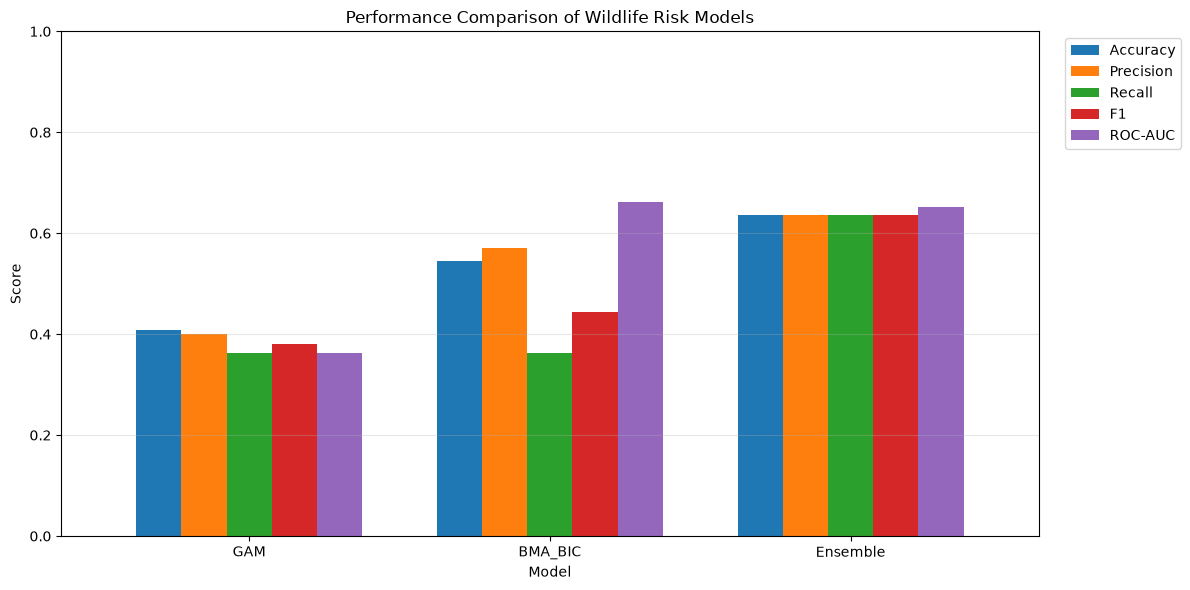

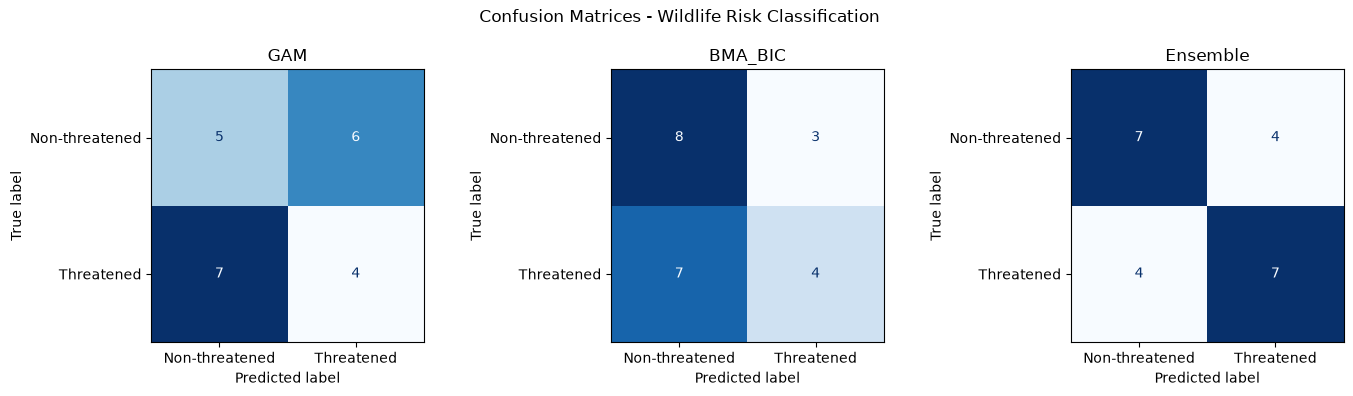

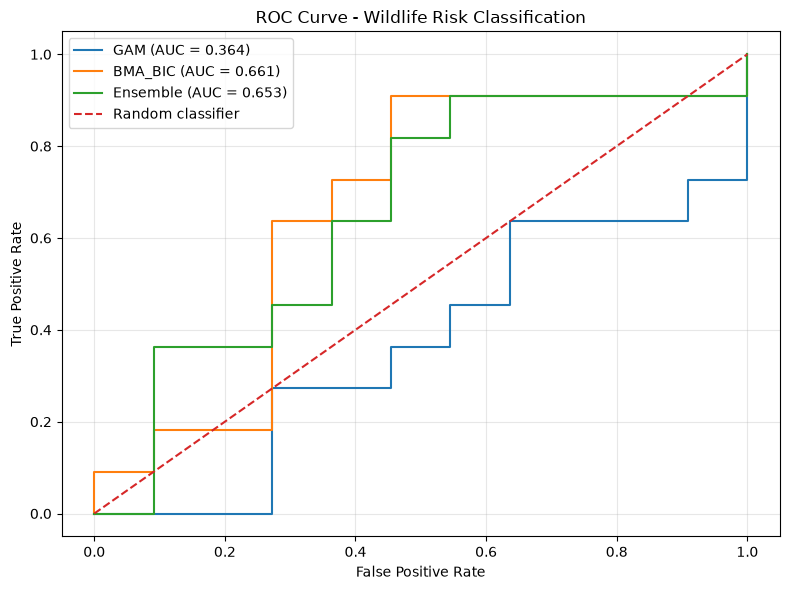


All presentation graphs saved in:
D:\wildlife\outputs

Files:
confusion_matrices.png
model_performance_comparison.png
roc_curves.png


In [49]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)

PROJECT_DIR = Path(r"D:\wildlife")
GBIF_DIR = PROJECT_DIR / "datasets" / "gbif"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

# 1. MODEL PERFORMANCE COMPARISON
metrics = [
    "Accuracy",
    "Precision",
    "Sensitivity_Recall",
    "F1_Score",
    "ROC_AUC"
]

plot_df = results_df.set_index("Model")[metrics]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.75
)

plt.title("Performance Comparison of Wildlife Risk Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(
    ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 2. CONFUSION MATRICES
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, (name, (pred, prob)) in zip(
    axes,
    predictions.items()
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        pred,
        display_labels=["Non-threatened", "Threatened"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(name)

plt.suptitle("Confusion Matrices - Wildlife Risk Classification")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 3. ROC CURVES
plt.figure(figsize=(8, 6))

for name, (pred, prob) in predictions.items():

    fpr, tpr, thresholds = roc_curve(y_test, prob)

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

plt.title("ROC Curve - Wildlife Risk Classification")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


print("\nAll presentation graphs saved in:")
print(OUTPUT_DIR)

print("\nFiles:")
for file in OUTPUT_DIR.glob("*.png"):
    print(file.name)


ENVIRONMENTAL FACTOR COMPARISON
Variable  NonThreatened_Mean  Threatened_Mean  Mean_Difference  MannWhitney_U  P_Value  Standardized_Mean_Difference  Adjusted_P_Value  Significant_FDR_0.05
    BIO1             18.2676          21.3488           3.0812         1210.0   0.0247                        0.4629            0.0493                  True
    BIO4              3.5735           2.2555          -1.3180          752.0   0.1020                       -0.5079            0.1530                 False
    BIO5             28.5348          29.0084           0.4736          975.0   0.8021                        0.0969            0.9020                 False
    BIO6              7.7086          13.2902           5.5816         1262.0   0.0072                        0.5765            0.0215                  True
   BIO12           1269.1444        1857.1190         587.9746         1263.0   0.0070                        0.6640            0.0215                  True
   BIO15             59.0

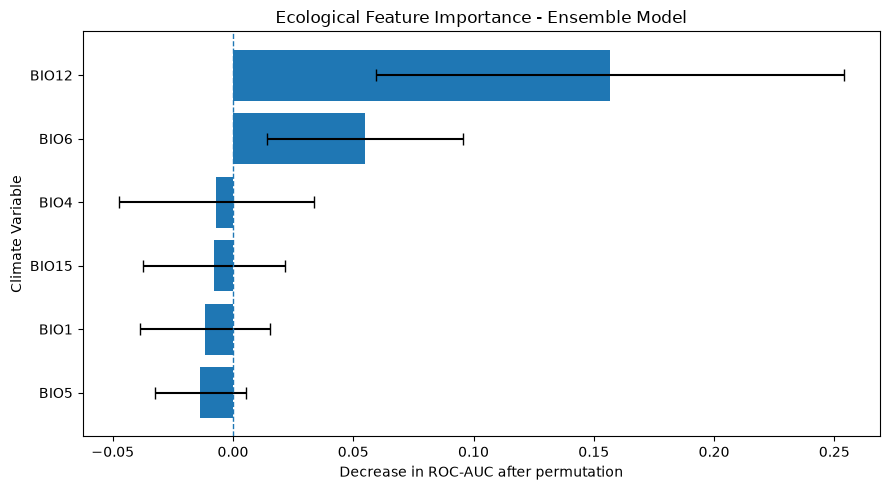


Results saved in: D:\wildlife\outputs


In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, VotingClassifier
from sklearn.inspection import permutation_importance

# ------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------

PROJECT_DIR = Path(r"D:\wildlife")
GBIF_DIR = PROJECT_DIR / "datasets" / "gbif"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

df = pd.read_csv(
    GBIF_DIR / "wildlife_modeling_dataset.csv"
)

FEATURES = ["BIO1", "BIO4", "BIO5", "BIO6", "BIO12", "BIO15"]

X = df[FEATURES]
y = df["risk_target"]

# ------------------------------------------------
# 2. COMPARE ENVIRONMENTAL FACTORS
# ------------------------------------------------

factor_results = []

for feature in FEATURES:

    non_threatened = df.loc[df["risk_target"] == 0, feature].dropna()
    threatened = df.loc[df["risk_target"] == 1, feature].dropna()

    # Mann-Whitney U test
    statistic, p_value = mannwhitneyu(
        threatened,
        non_threatened,
        alternative="two-sided"
    )

    # Standardized mean difference (effect size)
    pooled_sd = np.sqrt(
        (
            (len(threatened)-1) * threatened.var()
            + (len(non_threatened)-1) * non_threatened.var()
        ) /
        (len(threatened) + len(non_threatened) - 2)
    )

    effect_size = (
        threatened.mean() - non_threatened.mean()
    ) / pooled_sd if pooled_sd > 0 else np.nan

    factor_results.append({
        "Variable": feature,
        "NonThreatened_Mean": non_threatened.mean(),
        "Threatened_Mean": threatened.mean(),
        "Mean_Difference": threatened.mean() - non_threatened.mean(),
        "MannWhitney_U": statistic,
        "P_Value": p_value,
        "Standardized_Mean_Difference": effect_size
    })

factor_df = pd.DataFrame(factor_results)

# Correct for multiple statistical tests
factor_df["Adjusted_P_Value"] = multipletests(
    factor_df["P_Value"],
    method="fdr_bh"
)[1]

factor_df["Significant_FDR_0.05"] = (
    factor_df["Adjusted_P_Value"] < 0.05
)

# ------------------------------------------------
# 3. ENSEMBLE FEATURE IMPORTANCE
# ------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42
)

extra = ExtraTreesClassifier(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42
)

ensemble_model = VotingClassifier(
    estimators=[
        ("random_forest", rf),
        ("extra_trees", extra)
    ],
    voting="soft"
)

ensemble_model.fit(X_train, y_train)

# Permutation importance on held-out test set
importance = permutation_importance(
    ensemble_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=30,
    random_state=42
)

importance_df = pd.DataFrame({
    "Variable": FEATURES,
    "Importance_Mean": importance.importances_mean,
    "Importance_Std": importance.importances_std
}).sort_values(
    "Importance_Mean",
    ascending=False
)

# ------------------------------------------------
# 4. SAVE RESULTS
# ------------------------------------------------

factor_df.to_csv(
    OUTPUT_DIR / "ecological_factor_statistics.csv",
    index=False
)

importance_df.to_csv(
    OUTPUT_DIR / "ecological_feature_importance.csv",
    index=False
)

# ------------------------------------------------
# 5. DISPLAY RESULTS
# ------------------------------------------------

print("\nENVIRONMENTAL FACTOR COMPARISON")
print(factor_df.round(4).to_string(index=False))

print("\nENSEMBLE PERMUTATION FEATURE IMPORTANCE")
print(importance_df.round(4).to_string(index=False))

print("\nStatistically significant after FDR correction:")
print(
    factor_df.loc[
        factor_df["Significant_FDR_0.05"],
        "Variable"
    ].tolist()
)

# ------------------------------------------------
# 6. FEATURE IMPORTANCE GRAPH
# ------------------------------------------------

plt.figure(figsize=(9, 5))

plt.barh(
    importance_df["Variable"],
    importance_df["Importance_Mean"],
    xerr=importance_df["Importance_Std"],
    capsize=4
)

plt.axvline(0, linestyle="--", linewidth=1)
plt.xlabel("Decrease in ROC-AUC after permutation")
plt.ylabel("Climate Variable")
plt.title("Ecological Feature Importance - Ensemble Model")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "ecological_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nResults saved in:", OUTPUT_DIR)

In [51]:
import pandas as pd
import rasterio
from pathlib import Path

PROJECT_DIR = Path(r"D:\wildlife")
GBIF_DIR = PROJECT_DIR / "datasets" / "gbif"
WC_DIR = PROJECT_DIR / "datasets" / "worldclim"

# Original occurrence-level values, before conversion
raw = pd.read_csv(
    GBIF_DIR / "gbif_occurrences_with_climate.csv"
)

variables = ["BIO1", "BIO4", "BIO5", "BIO6", "BIO12", "BIO15"]

print("RAW OCCURRENCE VALUE RANGES")

for variable in variables:
    print(f"\n{variable}")
    print(raw[variable].describe().round(3))

print("\nRASTER METADATA")

for number in [1, 4, 5, 6, 12, 15]:
    path = WC_DIR / f"wc2.1_10m_bio_{number}.tif"

    with rasterio.open(path) as src:
        print(
            f"BIO{number}: "
            f"dtype={src.dtypes[0]}, "
            f"nodata={src.nodata}, "
            f"scale={src.scales[0]}, "
            f"offset={src.offsets[0]}"
        )

RAW OCCURRENCE VALUE RANGES

BIO1
count    5801.000
mean       18.459
std         7.449
min       -14.640
25%        15.941
50%        19.742
75%        24.470
max        28.680
Name: BIO1, dtype: float64

BIO4
count    5801.000
mean      329.867
std       270.836
min        13.885
25%       101.388
50%       267.001
75%       481.868
max      1369.736
Name: BIO4, dtype: float64

BIO5
count    5801.000
mean       28.299
std         5.769
min         5.221
25%        26.093
50%        29.397
75%        31.969
max        45.239
Name: BIO5, dtype: float64

BIO6
count    5801.000
mean        8.740
std        10.469
min       -34.414
25%         4.431
50%         9.824
75%        16.473
max        24.100
Name: BIO6, dtype: float64

BIO12
count    5801.000
mean     1426.447
std       954.150
min         0.000
25%       603.000
50%      1353.000
75%      1985.000
max      6801.000
Name: BIO12, dtype: float64

BIO15
count    5801.000
mean       60.914
std        28.702
min         0.000
25%   

In [52]:
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_DIR = Path(r"D:\wildlife")
GBIF_DIR = PROJECT_DIR / "datasets" / "gbif"

# Load original occurrence-level climate data
occ = pd.read_csv(
    GBIF_DIR / "gbif_occurrences_with_climate.csv"
)

species = pd.read_csv(
    GBIF_DIR / "gbif_verified_species_91.csv"
)

BIO_VARIABLES = ["BIO1", "BIO4", "BIO5", "BIO6", "BIO12", "BIO15"]

# Aggregate original raster values by species
species_climate = (
    occ.groupby("species_id")[BIO_VARIABLES]
    .median()
    .reset_index()
)

# Apply correct WorldClim unit conversions
species_climate["BIO4"] = species_climate["BIO4"] / 100

# BIO1, BIO5, BIO6, BIO12 and BIO15 remain unchanged

# Merge with all 91 verified species
model_data = species[
    ["species_id", "requested_name", "risk_target", "category"]
].merge(
    species_climate,
    on="species_id",
    how="left"
)

# Retain species with complete environmental data
model_df = model_data.dropna(
    subset=BIO_VARIABLES
).copy()

# Save corrected datasets separately
model_data.to_csv(
    GBIF_DIR / "wildlife_climate_corrected_all.csv",
    index=False
)

model_df.to_csv(
    GBIF_DIR / "wildlife_modeling_dataset.csv",
    index=False
)

print("CORRECTED DATASET SUMMARY")
print("Total species:", len(model_data))
print("Complete species:", len(model_df))
print("Excluded species:", len(model_data) - len(model_df))

print("\nThreat distribution:")
print(model_df["risk_target"].value_counts())

print("\nCorrected climate statistics:")
print(model_df[BIO_VARIABLES].describe().round(3))

print("\nSaved corrected modelling dataset:")
print(GBIF_DIR / "wildlife_modeling_dataset.csv")

CORRECTED DATASET SUMMARY
Total species: 91
Complete species: 87
Excluded species: 4

Threat distribution:
risk_target
0    45
1    42
Name: count, dtype: int64

Corrected climate statistics:
         BIO1    BIO4    BIO5    BIO6     BIO12    BIO15
count  87.000  87.000  87.000  87.000    87.000   87.000
mean   19.755   2.937  28.763  10.403  1552.994   59.567
std     6.796   2.663   4.867  10.026   928.558   26.949
min    -4.095   0.266  13.452 -23.769    50.000   10.439
25%    16.886   0.814  27.086   6.361   819.500   37.715
50%    20.884   2.386  30.035  10.573  1592.000   57.086
75%    25.166   3.959  31.880  18.497  2160.500   81.635
max    28.097  12.434  37.438  22.978  4050.000  114.878

Saved corrected modelling dataset:
D:\wildlife\datasets\gbif\wildlife_modeling_dataset.csv


In [54]:
import pandas as pd

from pathlib import Path

PROJECT_DIR = Path(r"D:\wildlife")
GBIF_DIR = PROJECT_DIR / "datasets" / "gbif"

df = pd.read_csv(
    GBIF_DIR / "wildlife_modeling_dataset.csv"
)

print("DATASET VERIFICATION")
print("Rows:", len(df))
print("\nClimate means:")
print(df[["BIO1", "BIO4", "BIO5", "BIO6", "BIO12", "BIO15"]].mean().round(3))

print("\nThreat distribution:")
print(df["risk_target"].value_counts())

DATASET VERIFICATION
Rows: 87

Climate means:
BIO1       19.755
BIO4        2.937
BIO5       28.763
BIO6       10.403
BIO12    1552.994
BIO15      59.567
dtype: float64

Threat distribution:
risk_target
0    45
1    42
Name: count, dtype: int64


In [55]:
print("CURRENT MODEL INPUT CHECK")
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

print("\nTest climate means:")
print(X_test.mean().round(3))

print("\nCurrent model predictions:")
print("GAM:", gam_pred)
print("BMA:", bma_pred)
print("Ensemble:", ensemble_pred)

print("\nActual test labels:")
print(y_test.to_numpy())

CURRENT MODEL INPUT CHECK
Training samples: 65
Test samples: 22

Test climate means:
BIO1       19.257
BIO4        3.326
BIO5       28.558
BIO6        9.234
BIO12    1316.932
BIO15      64.932
dtype: float64

Current model predictions:
GAM: [1 0 1 1 0 0 1 1 0 0 1 1 0 0 0 0 1 0 0 0 1 1]
BMA: [0 0 0 0 0 0 1 0 0 1 1 0 0 0 0 1 1 1 0 0 1 0]
Ensemble: [1 0 1 0 1 0 1 0 0 1 1 0 0 0 1 1 1 1 0 0 1 0]

Actual test labels:
[0 1 1 0 1 1 1 0 0 0 0 0 0 1 1 1 1 0 0 1 1 0]


In [56]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

current_predictions = {
    "GAM": (gam_pred, gam_prob),
    "BMA_BIC": (bma_pred, bma_prob),
    "Ensemble": (ensemble_pred, ensemble_prob)
}

actual_results = []

for name, (pred, prob) in current_predictions.items():
    actual_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, prob)
    })

actual_results_df = pd.DataFrame(actual_results)

print(actual_results_df.round(4).to_string(index=False))

   Model  Accuracy  Precision  Recall     F1  ROC_AUC
     GAM    0.4091     0.4000  0.3636 0.3810   0.3636
 BMA_BIC    0.5455     0.5714  0.3636 0.4444   0.6612
Ensemble    0.6364     0.6364  0.6364 0.6364   0.6529


In [58]:
import pandas as pd
import numpy as np

from pathlib import Path
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, VotingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# ------------------------------------------------
# 1. LOAD CORRECTED DATASET
# ------------------------------------------------

PROJECT_DIR = Path(r"D:\wildlife")
GBIF_DIR = PROJECT_DIR / "datasets" / "gbif"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

df = pd.read_csv(
    GBIF_DIR / "wildlife_modeling_dataset.csv"
)

FEATURES = ["BIO1", "BIO4", "BIO5", "BIO6", "BIO12", "BIO15"]

X = df[FEATURES]
y = df["risk_target"]

# ------------------------------------------------
# 2. DEFINE ENSEMBLE MODEL
# ------------------------------------------------

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42
)

extra = ExtraTreesClassifier(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42
)

ensemble_model = VotingClassifier(
    estimators=[
        ("random_forest", rf),
        ("extra_trees", extra)
    ],
    voting="soft"
)

# ------------------------------------------------
# 3. GENERATE OUT-OF-FOLD PREDICTIONS
# ------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

risk_probabilities = cross_val_predict(
    ensemble_model,
    X,
    y,
    cv=cv,
    method="predict_proba"
)[:, 1]

predicted_classes = (
    risk_probabilities >= 0.5
).astype(int)

# ------------------------------------------------
# 4. BUILD SPECIES-LEVEL PREDICTION TABLE
# ------------------------------------------------

predictions_df = df[
    ["species_id", "requested_name", "category", "risk_target"]
].copy()

predictions_df["risk_probability"] = risk_probabilities

predictions_df["risk_probability_percent"] = (
    risk_probabilities * 100
).round(2)

predictions_df["predicted_risk"] = predicted_classes

predictions_df["predicted_category"] = predictions_df[
    "predicted_risk"
].map({
    0: "Non-threatened",
    1: "Threatened"
})

predictions_df["actual_category"] = predictions_df[
    "risk_target"
].map({
    0: "Non-threatened",
    1: "Threatened"
})

predictions_df["prediction_correct"] = (
    predictions_df["risk_target"]
    == predictions_df["predicted_risk"]
)

# Sort by highest predicted risk
predictions_df = predictions_df.sort_values(
    "risk_probability",
    ascending=False
)

# ------------------------------------------------
# 5. SAVE RESULTS
# ------------------------------------------------

prediction_path = (
    OUTPUT_DIR / "species_vulnerability_predictions.csv"
)

predictions_df.to_csv(
    prediction_path,
    index=False
)

# ------------------------------------------------
# 6. SUMMARY
# ------------------------------------------------

print("SPECIES VULNERABILITY PREDICTION SUMMARY")
print("Total species:", len(predictions_df))

print("\nPrediction distribution:")
print(predictions_df["predicted_category"].value_counts())

print("\nCross-validated accuracy:",
      round(predictions_df["prediction_correct"].mean(), 4))

print("\nHighest predicted risk species:")
print(
    predictions_df[
        ["requested_name", "category",
         "risk_probability_percent", "predicted_category"]
    ].head(10).to_string(index=False)
)

print("\nLowest predicted risk species:")
print(
    predictions_df[
        ["requested_name", "category",
         "risk_probability_percent", "predicted_category"]
    ].tail(10).to_string(index=False)
)

print("\nSaved to:", prediction_path)

SPECIES VULNERABILITY PREDICTION SUMMARY
Total species: 87

Prediction distribution:
predicted_category
Threatened        53
Non-threatened    34
Name: count, dtype: int64

Cross-validated accuracy: 0.5747

Highest predicted risk species:
          requested_name category  risk_probability_percent predicted_category
         Simias concolor       CR                     83.22         Threatened
        Mesomys occultus       LC                     80.16         Threatened
           Maxomys rajah       VU                     75.62         Threatened
    Crateromys australis       EN                     74.90         Threatened
   Platyrrhinus infuscus       LC                     70.57         Threatened
        Crocidura beatus       LC                     70.26         Threatened
      Chiropodomys major       LC                     69.90         Threatened
Neophocaena phocaenoides       VU                     69.37         Threatened
    Dasypus novemcinctus       LC                 